1. Sección: Introducción y pregunta de análisis
• Dataset: Cartas Yu-Gi-OH 
• Fuente: Keaggle https://www.kaggle.com/datasets/ioexception/yugioh-cards?select=cards.csv 
• Pregunta: ¿Cómo varían los promedios y la distribución de los puntos de Ataque (ATK) y Defensa (DEF) entre los distintos atributos de los monstruos de Yu-Gi-Oh!?
• Relevancia: Se combinan variables numéricas, como el ataque, la defensa y el nivel, con variables categóricas, como el atributo y el tipo de monstruo. Esto permite aplicar técnicas de estadística descriptiva, visualización de datos, análisis de correlación y regresión lineal para estudiar las relaciones entre las variables.

Instalación librerias necesarias en Vs code: 
1. Instalar pandas: python -m pip install pandas
2. Instalar numpy: No requiere
3. Instalar Matplotlib: python -m pip install matplotlib
4. Instalar Seaborn: python -m pip install Seaborn
5. Instalar Matplotlib.image
6. Instalar Plotly: python -m pip install plotly

In [24]:
## Llamar la libería Pandas 
import pandas as pd 
## Llamar liberia numpy 
import numpy as np
## Llamar la libería Matplotlib
import matplotlib.pyplot as plt
## Llamar la liberia Seaborn
import seaborn as sns
## Llamar la libreria imagen
import matplotlib.image as mpimg
## Llamar libreria Plotly 
import plotly.express as px
## Llamar la libreria scipy
import scipy as sp



2. Sección: Carga y exploración inicial "Información del archivo y características"

In [25]:
## Abrir los datos a partir de la ubicación

## Desde la laptop: datos = pd.read_csv("D:/Programación/Data_Analysis/Proyecto_Final/cards.csv")

## Desde la carpeta: 

from pathlib import Path

datos = pd.read_csv(Path.cwd() / "cards.csv")


In [26]:
### Comprobación: 

print("Dimensiones del conjunto de datos:", datos.shape)
display(datos.head())

Dimensiones del conjunto de datos: (14599, 29)


,id,name,type,desc,atk,def,level,race,attribute,scale,...,views,viewsweek,upvotes,downvotes,formats,treated_as,tcg_date,ocg_date,konami_id,has_effect
0,80181649,"""A Case for K9""",Spell Card,"When this card is activated: You can add 1 ""K9...",NaN,NaN,NaN,Continuous,NaN,NaN,...,432598,2478,0,0,TCG|OCG|Master Duel,NaN,2025-07-31,2025-03-22,21385.0,1
1,34541863,"""A"" Cell Breeding Device",Spell Card,"During each of your Standby Phases, put 1 A-Co...",NaN,NaN,NaN,Continuous,NaN,NaN,...,352610,1220,118,110,Duel Links|Common Charity|Edison|TCG|OCG|Maste...,NaN,2007-05-16,2007-02-15,7128.0,1
2,64163367,"""A"" Cell Incubator",Spell Card,Each time an A-Counter(s) is removed from play...,NaN,NaN,NaN,Continuous,NaN,NaN,...,245187,378,25,20,Duel Links|Common Charity|Edison|TCG|OCG|Maste...,NaN,2007-11-14,2007-07-21,7315.0,1
3,91231901,"""A"" Cell Recombination Device",Spell Card,Target 1 face-up monster on the field; send 1 ...,NaN,NaN,NaN,Quick-Play,NaN,NaN,...,251104,210,19,15,Duel Links|Common Charity|TCG|OCG|Master Duel,NaN,2016-11-03,2016-07-09,12653.0,1
4,73262676,"""A"" Cell Scatter Burst",Spell Card,"Select 1 face-up ""Alien"" monster you control. ...",NaN,NaN,NaN,Quick-Play,NaN,NaN,...,197528,274,12,4,Duel Links|Common Charity|Edison|TCG|OCG|Maste...,NaN,2007-02-28,2006-11-16,6994.0,1


In [27]:
from pathlib import Path

carpeta_imagenes = Path.cwd() / "Cards_Image"

print("¿Existe la carpeta?", carpeta_imagenes.is_dir())

if carpeta_imagenes.is_dir():
    imagenes = [archivo for archivo in carpeta_imagenes.rglob("*")
                if archivo.is_file()]

    print("Cantidad de archivos:", len(imagenes))
    print("Primeros archivos:")

    for archivo in imagenes[:10]:
        print(archivo.relative_to(Path.cwd()))

¿Existe la carpeta? True
Cantidad de archivos: 1
Primeros archivos:
Cards_Image\Cyberdark_End_Dragon.png


In [28]:
## Previsualización de datos mediante tabla 
## NaN (Ausencia de valor): Se da en cartas de Magia (Spell Card) o Trampa (Trap Card).Por reglas del juego, estas cartas no poseen la propiedad de Ataque.
datos

,id,name,type,desc,atk,def,level,race,attribute,scale,...,views,viewsweek,upvotes,downvotes,formats,treated_as,tcg_date,ocg_date,konami_id,has_effect
0,80181649,"""A Case for K9""",Spell Card,"When this card is activated: You can add 1 ""K9...",NaN,NaN,NaN,Continuous,NaN,NaN,...,432598,2478,0,0,TCG|OCG|Master Duel,NaN,2025-07-31,2025-03-22,21385.0,1
1,34541863,"""A"" Cell Breeding Device",Spell Card,"During each of your Standby Phases, put 1 A-Co...",NaN,NaN,NaN,Continuous,NaN,NaN,...,352610,1220,118,110,Duel Links|Common Charity|Edison|TCG|OCG|Maste...,NaN,2007-05-16,2007-02-15,7128.0,1
2,64163367,"""A"" Cell Incubator",Spell Card,Each time an A-Counter(s) is removed from play...,NaN,NaN,NaN,Continuous,NaN,NaN,...,245187,378,25,20,Duel Links|Common Charity|Edison|TCG|OCG|Maste...,NaN,2007-11-14,2007-07-21,7315.0,1
3,91231901,"""A"" Cell Recombination Device",Spell Card,Target 1 face-up monster on the field; send 1 ...,NaN,NaN,NaN,Quick-Play,NaN,NaN,...,251104,210,19,15,Duel Links|Common Charity|TCG|OCG|Master Duel,NaN,2016-11-03,2016-07-09,12653.0,1
4,73262676,"""A"" Cell Scatter Burst",Spell Card,"Select 1 face-up ""Alien"" monster you control. ...",NaN,NaN,NaN,Quick-Play,NaN,NaN,...,197528,274,12,4,Duel Links|Common Charity|Edison|TCG|OCG|Maste...,NaN,2007-02-28,2006-11-16,6994.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14594,23720856,Zubababancho Gagagacoat,Effect Monster,"If you control a ""Zubaba"" or ""Gagaga"" monster ...",1800.0,100.0,4.0,Warrior,EARTH,NaN,...,421904,1092,5,2,Duel Links|Common Charity|TCG|OCG|Master Duel,NaN,2020-01-16,2019-11-09,14921.0,1
14595,43256007,Zuijin of the Ice Barrier,Effect Monster,You can Tribute this card; Special Summon 1 Le...,500.0,300.0,2.0,Warrior,WATER,NaN,...,75752,147,4,1,TCG|OCG|Master Duel,NaN,2021-02-18,2020-11-21,15896.0,1
14596,7459013,"Zure, Knight of Dark World",Normal Monster,The name of this illustrious knight is known b...,1800.0,1500.0,4.0,Fiend,DARK,NaN,...,101779,189,5,0,Duel Links|Common Charity|Edison|TCG|OCG|Maste...,NaN,2005-11-05,2005-08-11,6497.0,0
14597,67547370,Zushin the Sleeping Giant,Effect Monster,Cannot be Normal Summoned/Set. Must be Special...,0.0,0.0,10.0,Warrior,EARTH,NaN,...,38223,126,9,0,Duel Links|Common Charity|TCG|OCG|Master Duel,NaN,2016-08-18,2016-05-14,12541.0,1


In [29]:
# Información de datos filas y columnas 
datos.shape

(14599, 29)

In [30]:
## Estructura general 
datos.info()

<class 'pandas.DataFrame'>
RangeIndex: 14599 entries, 0 to 14598
Data columns (total 29 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               14599 non-null  int64  
 1   name             14599 non-null  str    
 2   type             14599 non-null  str    
 3   desc             14599 non-null  str    
 4   atk              9384 non-null   float64
 5   def              8910 non-null   float64
 6   level            9018 non-null   float64
 7   race             14596 non-null  str    
 8   attribute        9384 non-null   str    
 9   scale            390 non-null    float64
 10  archetype        8834 non-null   str    
 11  linkval          474 non-null    float64
 12  linkmarkers      474 non-null    str    
 13  image_url        14599 non-null  str    
 14  image_url_small  14599 non-null  str    
 15  ban_tcg          222 non-null    str    
 16  ban_ocg          199 non-null    str    
 17  ban_goat         73 non

In [31]:
## Resumen estadístico automático
datos.describe()

,id,atk,def,level,scale,linkval,views,viewsweek,upvotes,downvotes,konami_id,has_effect
count,1.459900e+04,9384.000000,8910.000000,9018.000000,390.000000,474.000000,1.459900e+04,14599.000000,14599.000000,14599.000000,14407.000000,14599.000000
mean,5.191718e+07,1520.430094,1287.828844,4.668108,4.256410,2.457806,1.786680e+05,669.631276,6.133913,1.232071,12164.594156,0.947257
std,3.815953e+07,963.754720,883.346773,2.498167,3.169731,0.996459,4.574072e+05,1898.641526,34.958286,6.290452,5232.444554,0.223528
min,4.830000e+02,-1.000000,-1.000000,0.000000,0.000000,1.000000,0.000000e+00,0.000000,0.000000,0.000000,-71.000000,0.000000
25%,2.469540e+07,800.000000,600.000000,3.000000,1.000000,2.000000,3.683050e+04,105.000000,1.000000,0.000000,7920.500000,1.000000
50%,4.972190e+07,1500.000000,1200.000000,4.000000,4.000000,2.000000,7.741200e+04,213.000000,3.000000,0.000000,11750.000000,1.000000
75%,7.511783e+07,2200.000000,2000.000000,6.000000,7.000000,3.000000,1.803115e+05,590.000000,6.000000,1.000000,15602.500000,1.000000
max,5.010000e+08,5000.000000,5000.000000,13.000000,13.000000,6.000000,2.574046e+07,89831.000000,2608.000000,533.000000,23902.000000,1.000000


3. Sección: — Limpieza y transformación

In [32]:
# Buscar en toda la tabla los datos vacíos, cuenta cuántos hay por columna y los muestra ordenados del que más faltantes tiene al que menos.
print("\nValores faltantes:")
print(datos.isnull().sum().sort_values(ascending=False))


Valores faltantes:
staple             14535
ban_goat           14526
treated_as         14457
ban_ocg            14400
ban_tcg            14377
scale              14209
linkval            14125
linkmarkers        14125
archetype           5765
def                 5689
level               5581
attribute           5215
atk                 5215
ocg_date             566
tcg_date             463
konami_id            192
formats               20
race                   3
name                   0
type                   0
desc                   0
id                     0
views                  0
image_url_small        0
image_url              0
viewsweek              0
downvotes              0
upvotes                0
has_effect             0
dtype: int64


In [33]:
## Porcentaje valores flotantes 

print("\nPorcentaje de valores faltantes:")
print((datos.isnull().mean() * 100).round(2).sort_values(ascending=False))


Porcentaje de valores faltantes:
staple             99.56
ban_goat           99.50
treated_as         99.03
ban_ocg            98.64
ban_tcg            98.48
scale              97.33
linkval            96.75
linkmarkers        96.75
archetype          39.49
def                38.97
level              38.23
attribute          35.72
atk                35.72
ocg_date            3.88
tcg_date            3.17
konami_id           1.32
formats             0.14
race                0.02
name                0.00
type                0.00
desc                0.00
id                  0.00
views               0.00
image_url_small     0.00
image_url           0.00
viewsweek           0.00
downvotes           0.00
upvotes             0.00
has_effect          0.00
dtype: float64


In [34]:
### Filas duplicadas 

print("\nFilas duplicadas:", datos.duplicated().sum())



Filas duplicadas: 0


In [35]:
### Filtrar cartas con atributo registrado

## Para buscar las filas que no estén vacías en la columna de atributo:

monstruos = datos.loc[
    datos["attribute"].notna()].copy()
 
print("Registros con atributo:", monstruos.shape[0])

# Comprobar y contar los atributos disponibles
print("\nCantidad de cartas por atributo:")
print(monstruos["attribute"].value_counts())

Registros con atributo: 9384

Cantidad de cartas por atributo:
attribute
DARK      2668
EARTH     2091
LIGHT     1967
WATER      954
WIND       867
FIRE       830
DIVINE       7
Name: count, dtype: int64


In [36]:
#### monstruos["atk"].notna() & (monstruos["atk"] >= 0): Revisa qué monstruos tienen Puntos de Ataque registrados y se asegura de que no sean valores negativos ni vacíos.
## .copy sirve para crear una copia completamente independiente de los datos filtrados.
analisis_atk = monstruos.loc[
    monstruos["atk"].notna() & (monstruos["atk"]>=0)].copy()

print("Registros válidos para ATK", len(analisis_atk))

analisis_def = monstruos.loc[
    monstruos["def"].notna() & (monstruos["def"]>=0)].copy()

print("Registros válidos para DEF", len(analisis_atk))
                             

Registros válidos para ATK 9300
Registros válidos para DEF 9300


4. Sección — Análisis exploratorio

In [37]:
## Estadística descriptiva de atk por atributo
# Agrupar los monstruos segun el atributo: analisis_atk_groupby("attribute") 
## .agg(["count", "mean", "median", "std", "min", "max"]) Paquete estadísticas

## APOYO IA 

# Estadística descriptiva de ATK por atributo

resumen_atk = analisis_atk.groupby("attribute")["atk"].agg(
    cantidad="count",
    promedio="mean",
    mediana="median",
    desviacion="std",
    minimo="min",
    maximo="max"
).round(2)

# Ordenar atributos de mayor a menor ATK promedio
ranking_atk = resumen_atk.sort_values(
    by="promedio", ascending=False
)

# Mostrar resultados
print("ESTADÍSTICAS Y RANKING DE ATK")
print(ranking_atk)

# Identificar atributos extremos
print("\nMayor ATK promedio:")
print(ranking_atk.head(1))

print("\nMenor ATK promedio:")
print(ranking_atk.tail(1))

ESTADÍSTICAS Y RANKING DE ATK
           cantidad  promedio  mediana  desviacion  minimo  maximo
attribute                                                         
DIVINE            2   4000.00   4000.0        0.00  4000.0  4000.0
LIGHT          1944   1621.30   1700.0     1014.05     0.0  5000.0
FIRE            825   1610.73   1600.0      883.74     0.0  3800.0
DARK           2639   1604.28   1600.0     1026.45     0.0  5000.0
WIND            864   1484.32   1500.0      875.84     0.0  4000.0
WATER           951   1414.46   1500.0      842.96     0.0  3600.0
EARTH          2075   1406.19   1400.0      896.39     0.0  5000.0

Mayor ATK promedio:
           cantidad  promedio  mediana  desviacion  minimo  maximo
attribute                                                         
DIVINE            2    4000.0   4000.0         0.0  4000.0  4000.0

Menor ATK promedio:
           cantidad  promedio  mediana  desviacion  minimo  maximo
attribute                                                

In [38]:
# Estadística descriptiva de DEF por atributo

resumen_def = analisis_def.groupby("attribute")["def"].agg(
    cantidad="count",
    promedio="mean",
    mediana="median",
    desviacion="std",
    minimo="min",
    maximo="max"
).round(2)

# Ordenar atributos de mayor a menor DEF promedio
ranking_def = resumen_def.sort_values(
    by="promedio", ascending=False
)

# Mostrar resultados
print("ESTADÍSTICAS Y RANKING DE DEF")
print(ranking_def)

ESTADÍSTICAS Y RANKING DE DEF
           cantidad  promedio  mediana  desviacion  minimo  maximo
attribute                                                         
DIVINE            2   4000.00   4000.0        0.00  4000.0  4000.0
LIGHT          1842   1405.78   1400.0      927.15     0.0  5000.0
DARK           2487   1299.55   1200.0      946.24     0.0  5000.0
WATER           911   1262.51   1200.0      767.38     0.0  3200.0
WIND            835   1262.46   1200.0      760.12     0.0  4000.0
EARTH          1996   1256.00   1200.0      844.12     0.0  5000.0
FIRE            782   1194.25   1200.0      848.29     0.0  3800.0


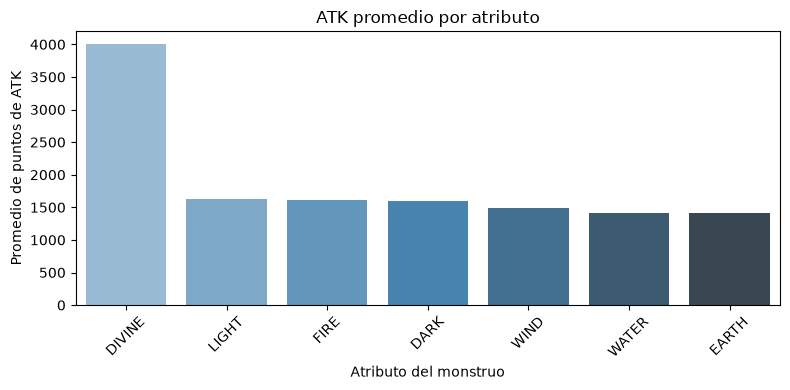

In [39]:
## Utilizando Seaborn

# Gráfico 1: ATK promedio por atributo

plt.figure(figsize=(8, 4))

sns.barplot(
    data=ranking_atk.reset_index(),
    x="attribute",
    y="promedio",
    hue="attribute",
    palette="Blues_d",
    legend=False
)

plt.title("ATK promedio por atributo")
plt.xlabel("Atributo del monstruo")
plt.ylabel("Promedio de puntos de ATK")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [40]:
# Buscar la carta con mayor ATK

# Excluir valores nulos para encontrar el máximo disponible
cartas_con_atk = analisis_atk.dropna(subset=["atk"])

# Encontrar la fila con el ATK más alto
indice_atk_max = cartas_con_atk["atk"].idxmax() ##Ubicación/indice de la fila
carta_mayor_atk = cartas_con_atk.loc[indice_atk_max]

# Mostrar la información de la carta
print("Carta con mayor ATK:")
print("Nombre:", carta_mayor_atk["name"])
print("ATK:", carta_mayor_atk["atk"])
print("Atributo:", carta_mayor_atk["attribute"])
print("Tipo:", carta_mayor_atk["type"])


Carta con mayor ATK:
Nombre: Cyberdark End Dragon
ATK: 5000.0
Atributo: DARK
Tipo: Fusion Monster


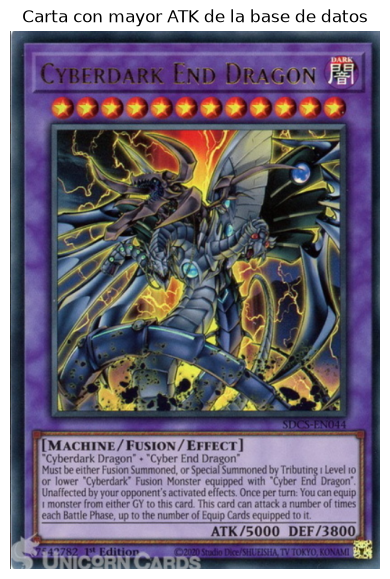

In [41]:
## Ruta imágen CARPETA 
ruta_imagen = (
    Path.cwd() / "Cards_Image" / "Cyberdark_End_Dragon.png"
)

imagen = mpimg.imread(ruta_imagen)

plt.figure(figsize=(4, 6))
plt.imshow(imagen)
plt.axis("off")

plt.title("Carta con mayor ATK de la base de datos")

plt.tight_layout()
plt.show()

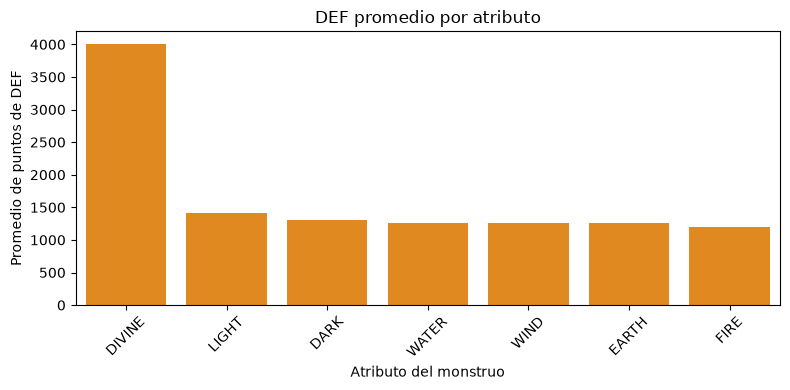

In [42]:
# Gráfico 2: DEF promedio por atributo

plt.figure(figsize=(8, 4))

sns.barplot(
    data=ranking_def.reset_index(),
    x="attribute",
    y="promedio",
    color="darkorange"
)

plt.title("DEF promedio por atributo")
plt.xlabel("Atributo del monstruo")
plt.ylabel("Promedio de puntos de DEF")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

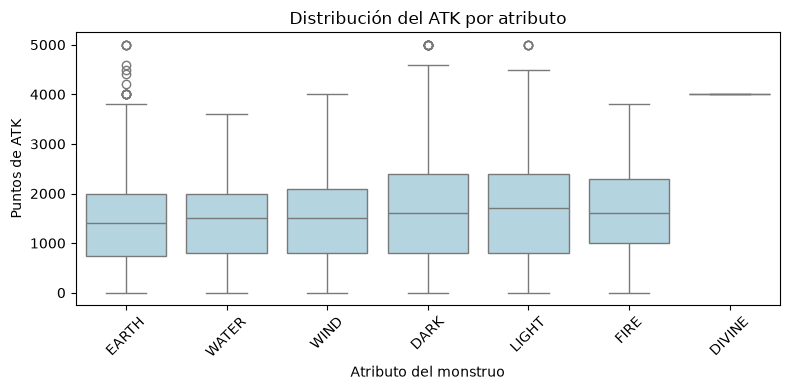

In [43]:
# Gráfico 3: Distribución del ATK por atributo

plt.figure(figsize=(8, 4))

sns.boxplot(
    data=analisis_atk,
    x="attribute",
    y="atk",
    color="lightblue"
)

plt.title("Distribución del ATK por atributo")
plt.xlabel("Atributo del monstruo")
plt.ylabel("Puntos de ATK")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [44]:
# Revisar la cantidad de cartas por atributo

cantidad_atk = analisis_atk.groupby("attribute")["atk"].agg(
    cantidad="count",
    minimo="min",
    maximo="max",
    promedio="mean",
    mediana="median"
).round(2)

print(cantidad_atk)


           cantidad  minimo  maximo  promedio  mediana
attribute                                             
DARK           2639     0.0  5000.0   1604.28   1600.0
DIVINE            2  4000.0  4000.0   4000.00   4000.0
EARTH          2075     0.0  5000.0   1406.19   1400.0
FIRE            825     0.0  3800.0   1610.73   1600.0
LIGHT          1944     0.0  5000.0   1621.30   1700.0
WATER           951     0.0  3600.0   1414.46   1500.0
WIND            864     0.0  4000.0   1484.32   1500.0


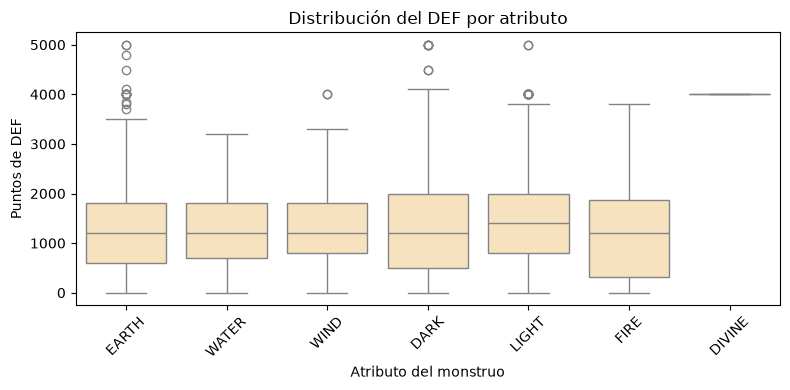

In [45]:
# Gráfico 4: Distribución del DEF por atributo

plt.figure(figsize=(8, 4))

sns.boxplot(
    data=analisis_def,
    x="attribute",
    y="def",
    color="moccasin"
)

plt.title("Distribución del DEF por atributo")
plt.xlabel("Atributo del monstruo")
plt.ylabel("Puntos de DEF")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

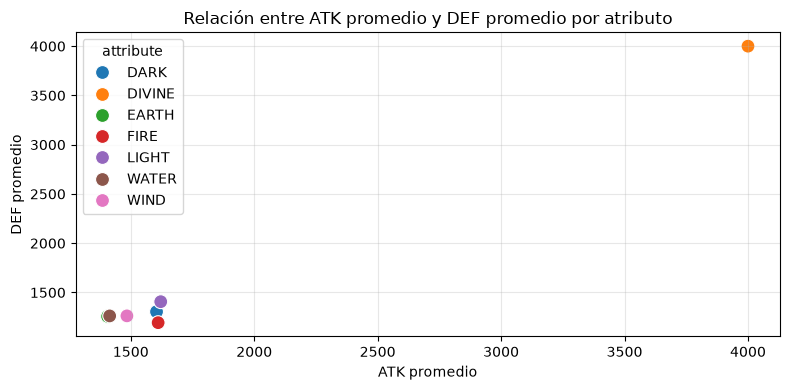

In [46]:

# Calcular los promedios de ATK y DEF por atributo
promedios = analisis_atk.groupby("attribute")[["atk", "def"]].mean().reset_index()

# Crear el gráfico de dispersión
plt.figure(figsize=(8, 4))

sns.scatterplot(
    data=promedios,
    x="atk",
    y="def",
    hue="attribute",
    s=100
)

plt.title("Relación entre ATK promedio y DEF promedio por atributo")
plt.xlabel("ATK promedio")
plt.ylabel("DEF promedio")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [47]:
# Preparar los datos para la prueba de hipótesis

datos_prueba_atk = analisis_atk[["attribute", "atk"]].copy()

# Asegurar que ATK sea numérico
datos_prueba_atk["atk"] = pd.to_numeric(
    datos_prueba_atk["atk"], errors="coerce"
)

# Eliminar filas sin atributo o sin ATK
datos_prueba_atk = datos_prueba_atk.dropna(
    subset=["attribute", "atk"]
)

# Mostrar cuántos monstruos hay en cada atributo
print("Cantidad de monstruos por atributo:")
print(datos_prueba_atk["attribute"].value_counts().sort_index())

Cantidad de monstruos por atributo:
attribute
DARK      2639
DIVINE       2
EARTH     2075
FIRE       825
LIGHT     1944
WATER      951
WIND       864
Name: count, dtype: int64


In [48]:
## Uso e implementación de la IA como Herramienta

# 1. Importamos la función kruskal desde la librería scipy
# Se utiliza porque nuestros datos no siguen una distribución normal
from scipy.stats import kruskal

# 2. Agrupamos los datos por el atributo de la carta (LIGHT, DARK, FIRE, etc.)
# y extraemos solo los valores numéricos de Ataque (ATK) para cada grupo.
# Esto genera una lista de arreglos: un arreglo de puntos de ataque por cada atributo.
grupos_atk = [
    grupo["atk"].values
    for _, grupo in datos_prueba_atk.groupby("attribute")
]

# 3. Ejecutamos la prueba de Kruskal-Wallis.
# El operador asterisco (*) "desempaqueta" la lista para pasarle a la función
# cada grupo de atributo como un argumento independiente.
estadistico_H, valor_p = kruskal(*grupos_atk)

# 4. Imprimimos el Estadístico H redondeado a 4 decimales.
# Mide qué tan alejadas o diferentes están las distribuciones entre sí.
print("Estadístico H:", round(estadistico_H, 4))

# 5. Imprimimos el valor p (p-value).
# Nos indica la probabilidad de que las diferencias encontradas sean pura casualidad.
print("Valor p:", valor_p)


Estadístico H: 93.3114
Valor p: 6.209859649837327e-18


La prueba demuestra que los puntos de Ataque (ATK) no están repartidos al azar entre los atributos. Existe una diferencia real y muy clara en la fuerza de ataque según el elemento del monstruo ($H = 93.31, p < 0.001$).En términos prácticos, esto significa que la categoría a la que pertenece una carta (como LIGHT, DARK, FIRE, etc.) sí influye directamente en qué tan alto o bajo suele ser su ataque. Hay elementos orientados a tener monstruos más fuertes en combate y otros con perfiles de ataque más bajos.

El Estadístico H (93.31): "Entre más alto sea este número, mayor es la diferencia real entre los grupos."El Valor p ($6.21 \times 10^{-18}$): "Como este número tiene 17 ceros a la izquierda (es prácticamente cero y menor a 0.05), podemos afirmar con total certeza estadística que el atributo del monstruo sí determina su nivel de ataque."



CONCLUSIONES: 

1. Preparación y Limpieza de los Datos:
Se filtró y acondicionó el dataset asegurando que las variables de Ataque (ATK) y Defensa (DEF) fueran de tipo numérico, eliminando registros nulos o inconsistentes en los atributos.

2. Análisis Exploratorio de Promedios y Distribución:
El caso atípico de DIVINE: A través de los gráficos de barras y dispersión, se observó que los monstruos de atributo DIVINE encabezan de forma extrema los promedios de ATK y DEF (alrededor de 4000 puntos), actuando como cartas de élite dentro del juego.

Atributos Estándar (LIGHT, DARK, FIRE, WIND, WATER, EARTH):
Los atributos LIGHT y DARK lideran los valores promedio de ataque (~1600 ATK) y muestran una mayor dispersión con presencia de valores atípicos (outliers) superiores a los 4500–5000 puntos en los boxplots.Atributos como WATER y EARTH presentan las medias de ataque más bajas (~1400 ATK), pero con defensas sólidas y distribuciones muy equilibradas.

3. Confirmación Estadística (Prueba de Kruskal-Wallis) Para validar si las diferencias observadas en las gráficas eran estadísticamente significativas y no fruto del azar, se aplicó la prueba no paramétrica de Kruskal-Wallis sobre los datos de ataque:Estadístico $H = 93.31$: Al ser un valor elevado, indica que existe una variabilidad considerable en los rangos de ataque entre los diferentes atributos.Valor $p = 6.21 \times 10^{-18}$ ($p < 0.001$): Al ser sustancialmente menor que el umbral de significancia estándar ($\alpha = 0.05$), se rechaza la hipótesis nula.

Se concluye con total certeza estadística que el atributo de un monstruo en Yu-Gi-Oh! determina directamente su perfil estadístico de combate (ATK y DEF). El diseño de las cartas asigna roles claros a cada atributo: desde cartas divinas de fuerza excepcional, pasando por atributos ofensivos principales (LIGHT y DARK), hasta elementos con enfoques más defensivos o balanceados.

In [49]:
#### Anexo
# 
#  Subir archivo VS-Code a drive.
 
from pathlib import Path

print("Carpeta de trabajo actual:")
print(Path.cwd())

print("\nArchivos y carpetas disponibles:")
for elemento in Path.cwd().iterdir():
    print(elemento.name)

Carpeta de trabajo actual:
d:\Programación\Data_Analysis\Proyecto_Final

Archivos y carpetas disponibles:
cards.csv
Cards_Image
Card_Data_Analysis.ipynb


In [ ]:
## Ejecutar: 
# from pathlib import Path

# datos = pd.read_csv(Path.cwd() / "cards.csv")
